# Parte 3: modelo preditivo de saneamento. A RMSP está onde o seu perfil indica?

**Tema 2:** Ciência de Dados para diversidade, desigualdade social e meio ambiente, com foco na Região Metropolitana de São Paulo (RMSP).

**Pergunta principal:** quanto do acesso a esgotamento sanitário adequado de um município pode ser previsto pelo seu perfil socioeconômico e demográfico? Quais municípios da RMSP estão **abaixo do esperado** para esse perfil?

**Perguntas secundárias**
1. Qual modelo prevê melhor o percentual de domicílios com esgoto adequado: um modelo linear ou modelos baseados em árvores?
2. Quais variáveis mais pesam na previsão (renda, alfabetização, porte, composição racial, estado)?
3. Na RMSP, onde o déficit observado é maior do que o previsto, ou seja, não se explica pelo perfil do município e pede ação de gestão?

**Estratégia.** A RMSP tem só 39 municípios, pouco para treinar um modelo. Por isso o modelo é treinado com os **5.570 municípios do Brasil** (mesmas fontes do IBGE da Parte 1) e depois aplicado à RMSP. Para cada município da RMSP a previsão vem de um modelo que **não viu aquele município no treino** (previsão fora da amostra, *out-of-fold*).

In [1]:
import io, os, json, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import sklearn

pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6eaef', 'axes.axisbelow': True})
SEMENTE = 42
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


## 1. Carregamento dos dados

As mesmas quatro fontes da Parte 1 (IBGE, Censo 2022 e PIB 2023), agora com **todos os municípios do Brasil**.

In [2]:
URLS = {
    'municipios_ibge.csv': 'https://raw.githubusercontent.com/caioapolonio/eleicoes-2026/main/data/municipios_presidente_1t_2026.csv',
    'bruto_esgoto_municipios.csv': 'https://raw.githubusercontent.com/zxcortes/Saneamento-censo-2022-Analise_de_Dados/main/bruto_esgoto_municipios.csv',
}
for arquivo, url in URLS.items():
    if not os.path.exists(arquivo):
        urllib.request.urlretrieve(url, arquivo)

def ler_sidra(arquivo):
    # Tabelas do SIDRA: 4 linhas de título, 1º bloco de contagens até a linha "Fonte"
    linhas = open(arquivo, encoding='utf-8-sig').read().splitlines()
    fim = next(i for i, l in enumerate(linhas) if l.startswith('"Fonte'))
    df = pd.read_csv(io.StringIO('\n'.join(linhas[4:fim])), sep=';', dtype=str)
    df = df[df['Cód.'].str.fullmatch(r'\d{7}', na=False)]
    return df.rename(columns={'Cód.': 'cod_ibge', 'Município': 'municipio_uf'})

def para_numero(df):
    out = df.copy()
    for c in out.columns[2:]:
        out[c] = pd.to_numeric(out[c].str.strip().replace({'-': '0'}), errors='coerce')  # '-' = 0; 'X', '..' = NaN
    out['cod_ibge'] = out['cod_ibge'].astype(int)
    return out.drop(columns='municipio_uf')

mun_raw = pd.read_csv('municipios_ibge.csv')
esgoto = para_numero(ler_sidra('bruto_esgoto_municipios.csv')).rename(columns={
    'Total': 'dom_total', 'Rede geral ou pluvial': 'dom_esg_rede',
    'Fossa séptica ou fossa filtro não ligada à rede': 'dom_esg_fossa_septica'})
print('Municípios (base IBGE):', mun_raw.shape, '| Esgoto (SIDRA 6805):', esgoto.shape)

Municípios (base IBGE): (5571, 52) | Esgoto (SIDRA 6805): (5570, 8)


## 2. Pré-processamento

**Alvo (y):** `pct_esgoto_adequado` = % de domicílios com esgoto por rede geral ou fossa séptica (mesma definição do indicador I4 da Parte 1).

**Variáveis explicativas (X):** só características socioeconômicas, demográficas e territoriais. **Nenhuma variável de saneamento** entra como explicativa (água, lixo), para não "vazar" o alvo.

| Variável | Transformação | Por quê |
|---|---|---|
| População 2022 | log | distribuição muito assimétrica (de 800 hab. a 11 milhões) |
| PIB per capita 2023 | log | idem; outliers de polos industriais |
| Renda domiciliar per capita mediana | log | idem |
| Razão renda média / mediana | nenhuma | concentração de renda (indicador I1) |
| Taxa de alfabetização 15+ | nenhuma | educação (I5) |
| % população negra, % indígena, % amarela | nenhuma | composição racial (I3) |
| Unidade da Federação (UF) | one-hot (27 colunas) | o saneamento depende muito da política e da companhia estadual |

As colunas eleitorais da base original são descartadas, como na Parte 1.

In [3]:
COLS = {'ibge_code': 'cod_ibge', 'municipality': 'municipio', 'state': 'uf', 'region': 'regiao',
        'population_2022': 'populacao_2022', 'gdp_per_capita_2023_brl': 'pib_pc_2023',
        'income_per_capita_mean_2022': 'renda_pc_media', 'income_per_capita_median_2022': 'renda_pc_mediana',
        'pct_black_2022': 'pct_preta', 'pct_brown_2022': 'pct_parda', 'pct_yellow_2022': 'pct_amarela',
        'pct_indigenous_2022': 'pct_indigena', 'literacy_rate_15plus_2022': 'taxa_alfab_15m'}
mun = mun_raw[list(COLS)].rename(columns=COLS)
mun['cod_ibge'] = mun['cod_ibge'].astype(int)

br = mun.merge(esgoto[['cod_ibge', 'dom_total', 'dom_esg_rede', 'dom_esg_fossa_septica']],
               on='cod_ibge', how='left', validate='1:1')
print('Valores ausentes antes da limpeza:')
print(br.isna().sum()[lambda s: s > 0])

Valores ausentes antes da limpeza:
populacao_2022           1
pib_pc_2023              1
renda_pc_media           1
renda_pc_mediana         1
pct_preta                1
pct_parda                1
pct_amarela              1
pct_indigena             1
taxa_alfab_15m           1
dom_total                1
dom_esg_rede             1
dom_esg_fossa_septica    1
dtype: int64


In [4]:
# O único município sem dados é Boa Esperança do Norte (MT), criado depois do Censo 2022.
# Sem alvo nem variáveis, ele é removido (não faz sentido imputar o alvo).
print(br.loc[br.isna().any(axis=1), ['cod_ibge', 'municipio', 'uf']])
br = br.dropna().reset_index(drop=True)

br['pct_esgoto_adequado'] = 100 * (br['dom_esg_rede'] + br['dom_esg_fossa_septica']) / br['dom_total']
br['log_populacao'] = np.log(br['populacao_2022'])
br['log_pib_pc'] = np.log(br['pib_pc_2023'])
br['log_renda_mediana'] = np.log(br['renda_pc_mediana'])
br['razao_media_mediana'] = br['renda_pc_media'] / br['renda_pc_mediana']
br['pct_negra'] = br['pct_preta'] + br['pct_parda']

# Checagens de qualidade
assert br['cod_ibge'].is_unique
assert br['pct_esgoto_adequado'].between(0, 100).all()
assert (br['renda_pc_mediana'] > 0).all() and (br['pib_pc_2023'] > 0).all()
print('Base final:', br.shape)
br['pct_esgoto_adequado'].describe()

      cod_ibge               municipio  uf
5199   5101837  Boa Esperança do Norte  MT
Base final: (5570, 22)


count   5,570.00
mean       51.61
std        30.13
min         0.00
25%        24.79
50%        53.80
75%        78.03
max       100.00
Name: pct_esgoto_adequado, dtype: float64

Municípios da RMSP na base: 39


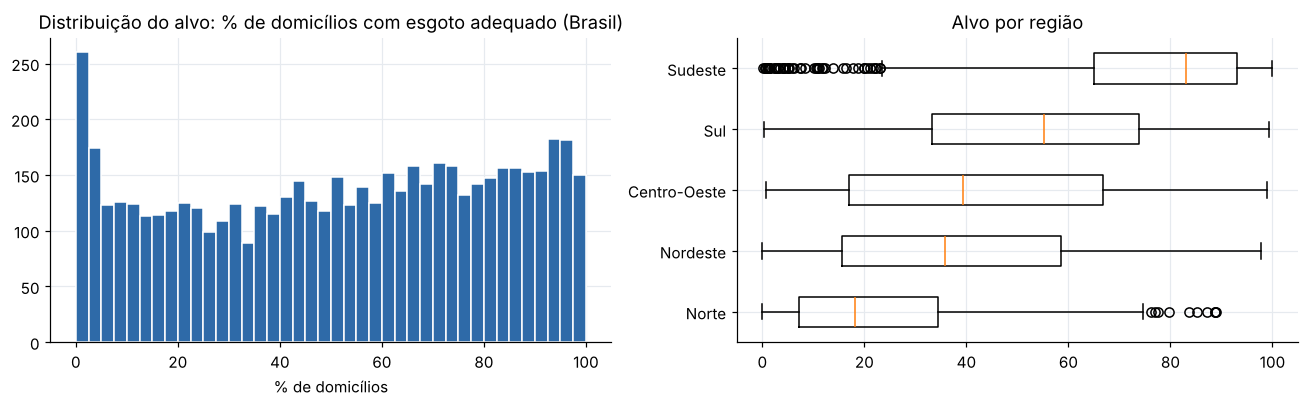

In [5]:
# Recorte RMSP (mesmos 39 códigos da Parte 1), usado só na etapa de aplicação
SUBREGIOES = {
    'Capital':  [3550308],
    'Norte':    [3509007, 3509205, 3516309, 3516408, 3528502],
    'Leste':    [3503901, 3506607, 3515707, 3518305, 3518800, 3523107, 3530607, 3539806, 3545001, 3546801, 3552502],
    'Sudeste':  [3513801, 3529401, 3543303, 3544103, 3547809, 3548708, 3548807],
    'Sudoeste': [3513009, 3515004, 3515103, 3522208, 3526209, 3549953, 3552809, 3556453],
    'Oeste':    [3505708, 3510609, 3522505, 3525003, 3534401, 3539103, 3547304],
}
mapa_sub = {c: s for s, cods in SUBREGIOES.items() for c in cods}
br['sub_regiao'] = br['cod_ibge'].map(mapa_sub)
br['rmsp'] = br['sub_regiao'].notna()
print('Municípios da RMSP na base:', br['rmsp'].sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(br['pct_esgoto_adequado'], bins=40, color='#2e6aa8', edgecolor='white')
ax[0].set_title('Distribuição do alvo: % de domicílios com esgoto adequado (Brasil)')
ax[0].set_xlabel('% de domicílios')
ordem = br.groupby('regiao')['pct_esgoto_adequado'].median().sort_values().index
ax[1].boxplot([br.loc[br['regiao'] == r, 'pct_esgoto_adequado'] for r in ordem], tick_labels=ordem, orientation='horizontal')
ax[1].set_title('Alvo por região')
plt.tight_layout(); plt.savefig('fig_p3_alvo.png', dpi=130); plt.show()

O alvo tem **distribuição larga e bimodal**: muitos municípios perto de 0% (sobretudo Norte e Nordeste, onde predomina a fossa rudimentar) e muitos perto de 100% (Sudeste). Isso justifica testar modelos não lineares, além do linear.

In [6]:
NUMERICAS = ['log_populacao', 'log_pib_pc', 'log_renda_mediana', 'razao_media_mediana',
             'taxa_alfab_15m', 'pct_negra', 'pct_indigena', 'pct_amarela']
X = pd.get_dummies(br[NUMERICAS + ['uf']], columns=['uf'], prefix='uf', dtype=float)
y = br['pct_esgoto_adequado']
COLS_UF = [c for c in X.columns if c.startswith('uf_')]
print('X:', X.shape, '| variáveis numéricas:', len(NUMERICAS), '| dummies de UF:', len(COLS_UF))

# Matriz de correlação (Spearman) das numéricas com o alvo
br[NUMERICAS + ['pct_esgoto_adequado']].corr(method='spearman')['pct_esgoto_adequado'].drop('pct_esgoto_adequado').sort_values()

X: (5570, 35) | variáveis numéricas: 8 | dummies de UF: 27


pct_negra             -0.40
razao_media_mediana   -0.09
pct_indigena          -0.07
log_populacao          0.20
pct_amarela            0.28
log_pib_pc             0.35
log_renda_mediana      0.48
taxa_alfab_15m         0.53
Name: pct_esgoto_adequado, dtype: float64

## 3. Divisão treino/teste e validação

- **Teste (20%)**: separado no início e usado **uma única vez**, no fim, para a métrica final.
- **Treino (80%)**: validação cruzada de 5 partes (*5-fold*) para comparar os modelos e ajustar hiperparâmetros.
- **Verificação extra (robustez espacial):** validação agrupada por UF (*GroupKFold*), em que o modelo é testado em estados que não viu no treino.

A divisão é **estratificada pela região**, para que treino e teste tenham a mesma proporção de municípios de cada região.

In [7]:
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
    X, y, br.index, test_size=0.2, random_state=SEMENTE, stratify=br['regiao'])
print(f'Treino: {len(X_tr)} municípios | Teste: {len(X_te)} municípios')
cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

Treino: 4456 municípios | Teste: 1114 municípios


## 4. Modelos

| Modelo | Tipo | Ideia | Pontos fortes | Pontos fracos |
|---|---|---|---|---|
| **Linha de base** (média) | — | prevê sempre a média do treino | referência mínima | não usa nenhuma informação |
| **Regressão Ridge** | linear | regressão linear com penalização L2 dos coeficientes (o α é escolhido por validação cruzada) | simples, rápida, coeficientes interpretáveis | só capta relações lineares e aditivas |
| **Random Forest** | conjunto de árvores (*bagging*) | média de centenas de árvores de decisão, cada uma treinada numa amostra diferente | capta não linearidades e interações; robusta a outliers | menos interpretável; mais lenta |
| **Gradient Boosting** (HistGradientBoosting) | conjunto de árvores (*boosting*) | árvores pequenas em sequência, cada uma corrigindo os erros da anterior | costuma ter o melhor desempenho em dados tabulares | mais hiperparâmetros; risco de sobreajuste se mal ajustado |

As duas árvores passam por uma **busca em grade** pequena de hiperparâmetros, feita só no treino.

In [8]:
t0 = time.time()
busca_rf = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
    {'min_samples_leaf': [1, 3, 5], 'max_features': [0.33, 0.6, 1.0]},
    cv=cv, scoring='neg_mean_absolute_error', n_jobs=1).fit(X_tr, y_tr)
print('Random Forest  | melhores parâmetros:', busca_rf.best_params_, f'| MAE CV {-busca_rf.best_score_:.2f}')

busca_gb = GridSearchCV(
    HistGradientBoostingRegressor(random_state=SEMENTE, l2_regularization=1.0, min_samples_leaf=20),
    {'learning_rate': [0.03, 0.06], 'max_leaf_nodes': [15, 31], 'max_iter': [300, 600]},
    cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1).fit(X_tr, y_tr)
print('Grad. Boosting | melhores parâmetros:', busca_gb.best_params_, f'| MAE CV {-busca_gb.best_score_:.2f}')
print(f'Tempo da busca: {time.time() - t0:.0f} s')

Random Forest  | melhores parâmetros: {'max_features': 0.33, 'min_samples_leaf': 1} | MAE CV 15.62


Grad. Boosting | melhores parâmetros: {'learning_rate': 0.03, 'max_iter': 600, 'max_leaf_nodes': 15} | MAE CV 15.42
Tempo da busca: 104 s


In [9]:
MODELOS = {
    'Linha de base (média)': DummyRegressor(),
    'Regressão Ridge': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    'Random Forest': busca_rf.best_estimator_,
    'Gradient Boosting': busca_gb.best_estimator_,
}
METRICAS = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

linhas = []
for nome, modelo in MODELOS.items():
    r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=METRICAS)
    linhas.append({'modelo': nome,
                   'MAE_cv': -r['test_MAE'].mean(), 'MAE_cv_dp': r['test_MAE'].std(),
                   'RMSE_cv': -r['test_RMSE'].mean(), 'R2_cv': r['test_R2'].mean(), 'R2_cv_dp': r['test_R2'].std()})
comp = pd.DataFrame(linhas).set_index('modelo')
comp

,MAE_cv,MAE_cv_dp,RMSE_cv,R2_cv,R2_cv_dp
modelo,,,,,
Linha de base (média),26.14,0.45,30.13,-0.00,0.00
Regressão Ridge,16.30,0.32,20.44,0.54,0.02
Random Forest,15.62,0.48,19.96,0.56,0.02
Gradient Boosting,15.42,0.50,19.97,0.56,0.02


## 5. Avaliação final no conjunto de teste

**Métricas** (o alvo está em pontos percentuais, p.p.):
- **MAE** (erro absoluto médio): em média, quantos p.p. a previsão erra. É a métrica principal, porque é fácil de interpretar.
- **RMSE** (raiz do erro quadrático médio): pune mais os erros grandes.
- **R²**: fração da variação do alvo explicada pelo modelo (0 = igual à média; 1 = perfeito).

In [10]:
teste = []
prev_teste = {}
for nome, modelo in MODELOS.items():
    modelo.fit(X_tr, y_tr)
    p = np.clip(modelo.predict(X_te), 0, 100)   # percentual não sai de 0-100
    prev_teste[nome] = p
    teste.append({'modelo': nome, 'MAE_teste': mean_absolute_error(y_te, p),
                  'RMSE_teste': root_mean_squared_error(y_te, p), 'R2_teste': r2_score(y_te, p)})
resultado = comp.join(pd.DataFrame(teste).set_index('modelo'))
MELHOR = resultado.drop('Linha de base (média)')['MAE_cv'].idxmin()   # escolha pela validação, não pelo teste
print('Modelo escolhido (menor MAE na validação cruzada):', MELHOR)
resultado[['MAE_cv', 'RMSE_cv', 'R2_cv', 'MAE_teste', 'RMSE_teste', 'R2_teste']]

Modelo escolhido (menor MAE na validação cruzada): Gradient Boosting


,MAE_cv,RMSE_cv,R2_cv,MAE_teste,RMSE_teste,R2_teste
modelo,,,,,,
Linha de base (média),26.14,30.13,-0.00,26.29,30.19,-0.00
Regressão Ridge,16.30,20.44,0.54,16.72,20.74,0.53
Random Forest,15.62,19.96,0.56,15.99,19.97,0.56
Gradient Boosting,15.42,19.97,0.56,15.66,19.86,0.57


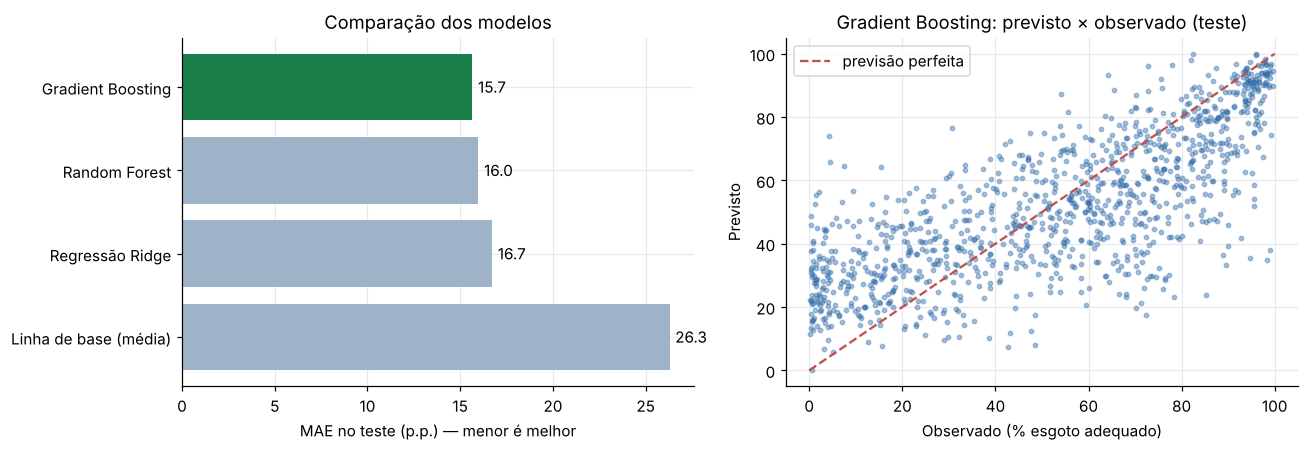

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
r = resultado.sort_values('MAE_teste')
cores = ['#1b7f4c' if n == MELHOR else '#9fb3c8' for n in r.index]
ax[0].barh(r.index, r['MAE_teste'], color=cores)
for i, v in enumerate(r['MAE_teste']):
    ax[0].text(v + 0.3, i, f'{v:.1f}', va='center')
ax[0].invert_yaxis(); ax[0].set_xlabel('MAE no teste (p.p.) — menor é melhor')
ax[0].set_title('Comparação dos modelos')

p = prev_teste[MELHOR]
ax[1].scatter(y_te, p, s=8, alpha=0.4, color='#2e6aa8')
ax[1].plot([0, 100], [0, 100], color='#c0504d', lw=1.5, ls='--', label='previsão perfeita')
ax[1].set_xlabel('Observado (% esgoto adequado)'); ax[1].set_ylabel('Previsto')
ax[1].set_title(f'{MELHOR}: previsto × observado (teste)'); ax[1].legend()
plt.tight_layout(); plt.savefig('fig_p3_modelos.png', dpi=130); plt.show()

### 5.1 Robustez espacial: o modelo funciona num estado que ele não viu?

Aqui a validação é agrupada por UF: cada estado fica inteiro fora do treino em uma das rodadas. Como a UF fica de fora, as dummies de UF não ajudam e são trocadas pela **macrorregião**.

In [12]:
X_reg = pd.get_dummies(br[NUMERICAS + ['regiao']], columns=['regiao'], dtype=float)
gkf = GroupKFold(n_splits=5)
esp = []
for nome in ['Linha de base (média)', 'Regressão Ridge', 'Random Forest', 'Gradient Boosting']:
    r = cross_validate(MODELOS[nome], X_reg, y, cv=gkf, groups=br['uf'], scoring=METRICAS)
    esp.append({'modelo': nome, 'MAE_uf_nova': -r['test_MAE'].mean(), 'R2_uf_nova': r['test_R2'].mean()})
espacial = pd.DataFrame(esp).set_index('modelo')
espacial

,MAE_uf_nova,R2_uf_nova
modelo,,
Linha de base (média),27.08,-0.26
Regressão Ridge,18.07,0.35
Random Forest,18.17,0.35
Gradient Boosting,18.10,0.33


Quando o estado é desconhecido, o erro aumenta e o R² cai. Isso confirma que **parte importante do saneamento é explicada por fatores estaduais** (companhia de saneamento, investimento histórico, regulação), e não só pelo perfil socioeconômico do município.

## 6. Quais variáveis mais pesam?

**Importância por permutação** no conjunto de teste: embaralha uma variável e mede quanto o MAE piora. As 27 dummies de UF são embaralhadas **juntas**, como uma variável só ("UF").

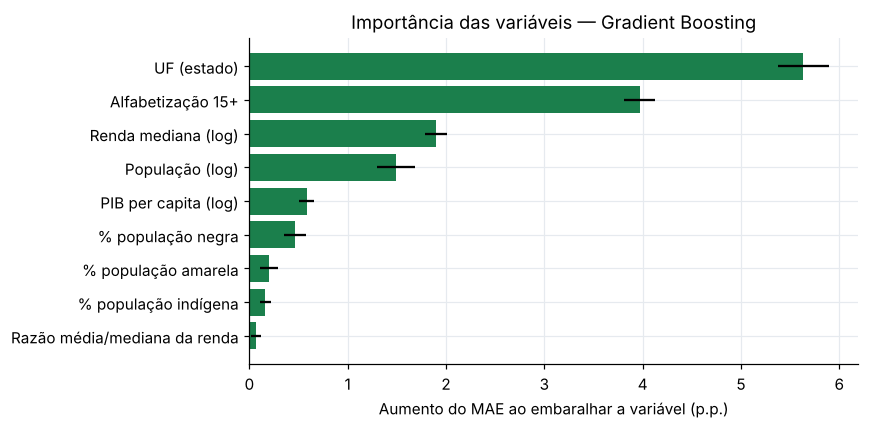

,variavel,aumento_MAE,dp
0,UF (estado),5.64,0.26
1,Alfabetização 15+,3.97,0.16
2,Renda mediana (log),1.90,0.11
3,População (log),1.49,0.20
4,PIB per capita (log),0.58,0.08
5,% população negra,0.47,0.11
6,% população amarela,0.20,0.09
7,% população indígena,0.16,0.06
8,Razão média/mediana da renda,0.07,0.05


In [13]:
modelo_final = MODELOS[MELHOR]
rng = np.random.default_rng(SEMENTE)
base_mae = mean_absolute_error(y_te, np.clip(modelo_final.predict(X_te), 0, 100))
grupos = {c: [c] for c in NUMERICAS} | {'uf': COLS_UF}
NOMES = {'log_populacao': 'População (log)', 'log_pib_pc': 'PIB per capita (log)',
         'log_renda_mediana': 'Renda mediana (log)', 'razao_media_mediana': 'Razão média/mediana da renda',
         'taxa_alfab_15m': 'Alfabetização 15+', 'pct_negra': '% população negra',
         'pct_indigena': '% população indígena', 'pct_amarela': '% população amarela', 'uf': 'UF (estado)'}
imp = []
for g, cols in grupos.items():
    aumentos = []
    for _ in range(10):
        Xp = X_te.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[perm]
        aumentos.append(mean_absolute_error(y_te, np.clip(modelo_final.predict(Xp), 0, 100)) - base_mae)
    imp.append({'variavel': NOMES[g], 'aumento_MAE': np.mean(aumentos), 'dp': np.std(aumentos)})
importancia = pd.DataFrame(imp).sort_values('aumento_MAE', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4))
d = importancia.iloc[::-1]
ax.barh(d['variavel'], d['aumento_MAE'], xerr=d['dp'], color='#1b7f4c')
ax.set_xlabel('Aumento do MAE ao embaralhar a variável (p.p.)')
ax.set_title(f'Importância das variáveis — {MELHOR}')
plt.tight_layout(); plt.savefig('fig_p3_importancia.png', dpi=130); plt.show()
importancia

## 7. Aplicação à RMSP: onde o déficit é maior do que o perfil explica?

Para cada município do Brasil, a previsão é feita **fora da amostra**: o modelo escolhido é treinado em 4/5 dos municípios e prevê o 1/5 restante, em 5 rodadas (`cross_val_predict`). Assim, nenhum município da RMSP é previsto por um modelo que o viu no treino.

**Resíduo = observado − previsto.**
- Resíduo **negativo**: o município tem **menos** esgoto adequado do que municípios de perfil semelhante. Esse é o "déficit inesperado", que pede investigação e ação de gestão.
- Resíduo **positivo**: está melhor do que o perfil indicaria.

In [14]:
br['previsto'] = np.clip(cross_val_predict(modelo_final, X, y, cv=cv), 0, 100)
br['residuo'] = br['pct_esgoto_adequado'] - br['previsto']
print(f"MAE fora da amostra — Brasil: {mean_absolute_error(br['pct_esgoto_adequado'], br['previsto']):.2f} p.p.")
rm = br[br['rmsp']].copy()
print(f"MAE fora da amostra — RMSP:   {mean_absolute_error(rm['pct_esgoto_adequado'], rm['previsto']):.2f} p.p.")
rm['dom_sem_esgoto_adequado'] = rm['dom_total'] - rm['dom_esg_rede'] - rm['dom_esg_fossa_septica']
# Domicílios "a mais" sem esgoto adequado em relação ao esperado (só quando o resíduo é negativo)
rm['dom_deficit_inesperado'] = (-rm['residuo']).clip(lower=0) / 100 * rm['dom_total']
cols = ['municipio', 'sub_regiao', 'pct_esgoto_adequado', 'previsto', 'residuo', 'dom_deficit_inesperado']
print('\nMaior déficit inesperado (observado bem abaixo do previsto):')
display(rm.sort_values('residuo')[cols].head(10).round(1))
print('Acima do esperado:')
display(rm.sort_values('residuo', ascending=False)[cols].head(5).round(1))

MAE fora da amostra — Brasil: 15.39 p.p.
MAE fora da amostra — RMSP:   6.90 p.p.

Maior déficit inesperado (observado bem abaixo do previsto):


,municipio,sub_regiao,pct_esgoto_adequado,previsto,residuo,dom_deficit_inesperado
3790,Santa Isabel,Leste,68.70,90.60,-21.90,"4,110.10"
3587,Mairiporã,Norte,72.30,94.20,-21.90,"7,242.70"
3435,Embu-Guaçu,Sudoeste,69.30,87.70,-18.40,"4,298.80"
3704,Pirapora do Bom Jesus,Oeste,73.80,91.40,-17.60,"1,075.80"
3563,Juquitiba,Sudoeste,60.40,77.60,-17.20,"1,720.90"
3411,Cotia,Sudoeste,81.90,95.90,-14.00,"13,422.80"
3795,Santana de Parnaíba,Oeste,82.60,96.30,-13.80,"7,195.10"
3370,Cajamar,Norte,83.30,96.00,-12.80,"4,170.70"
3900,Vargem Grande Paulista,Sudoeste,86.30,97.70,-11.50,"2,027.40"
3825,São Lourenço da Serra,Sudoeste,68.90,79.10,-10.20,594.50


Acima do esperado:


,municipio,sub_regiao,pct_esgoto_adequado,previsto,residuo,dom_deficit_inesperado
3711,Poá,Leste,96.80,93.00,3.80,0.00
3331,Barueri,Oeste,97.90,95.00,3.00,0.00
3419,Diadema,Sudeste,98.10,95.70,2.40,0.00
3851,Suzano,Leste,93.60,91.40,2.20,0.00
3812,São Caetano do Sul,Sudeste,99.80,97.80,2.00,0.00


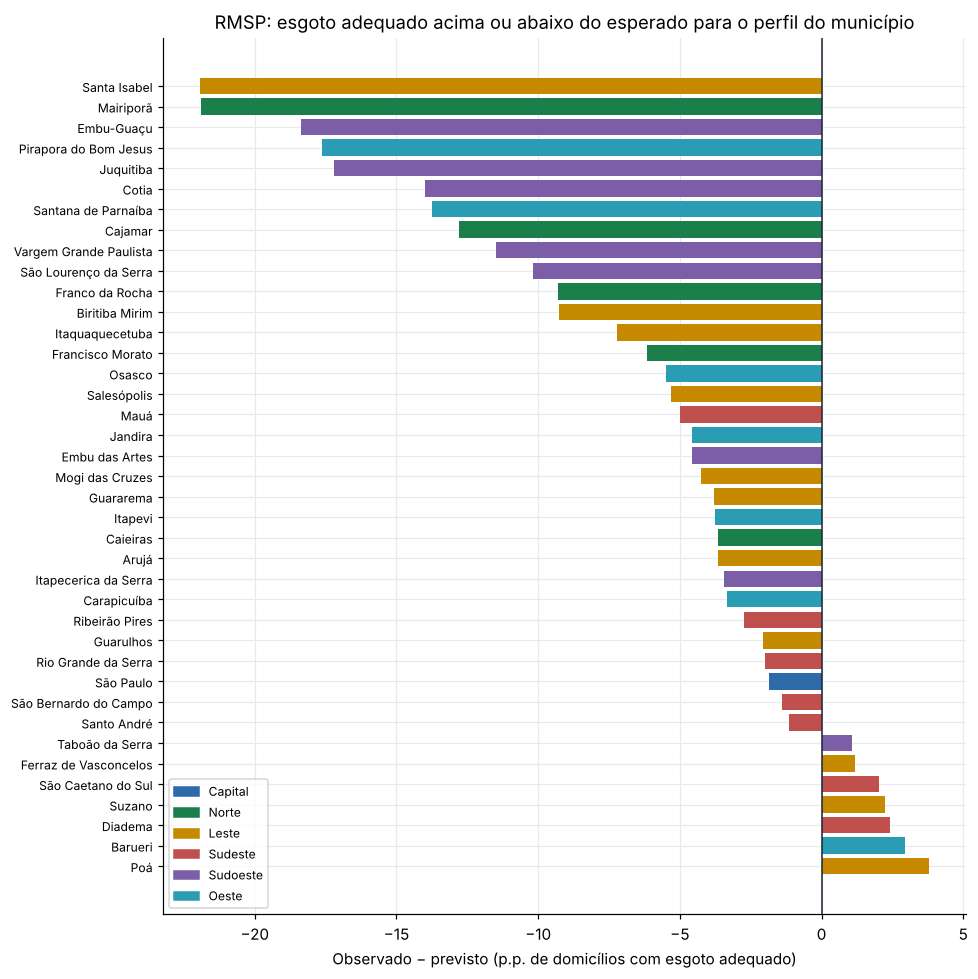

Soma de domicílios em déficit inesperado na RMSP: 209,204


,residuo
sub_regiao,
Norte,-10.80
Sudoeste,-9.80
Oeste,-6.50
Leste,-4.60
Capital,-1.90
Sudeste,-1.10


In [15]:
CORES_SUB = {'Capital': '#2e6aa8', 'Norte': '#1b7f4c', 'Leste': '#c58a00',
             'Sudeste': '#c0504d', 'Sudoeste': '#7b5ea7', 'Oeste': '#2a9db5'}
d = rm.sort_values('residuo')
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(d['municipio'], d['residuo'], color=d['sub_regiao'].map(CORES_SUB))
ax.axvline(0, color='#1a2433', lw=1)
ax.set_xlabel('Observado − previsto (p.p. de domicílios com esgoto adequado)')
ax.set_title('RMSP: esgoto adequado acima ou abaixo do esperado para o perfil do município')
ax.tick_params(axis='y', labelsize=8); ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in CORES_SUB.items()], loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig('fig_p3_rmsp_residuo.png', dpi=130); plt.show()

print(f"Soma de domicílios em déficit inesperado na RMSP: {rm['dom_deficit_inesperado'].sum():,.0f}")
rm.groupby('sub_regiao')[['residuo']].mean().sort_values('residuo').round(1)

## 8. Exportação para o data app (Parte 2)

O app lê estes arquivos da pasta `data/`:
- `resultados_modelo.json`: métricas de todos os modelos, modelo escolhido, hiperparâmetros e importância das variáveis;
- `rmsp_previsoes.csv`: observado, previsto e resíduo dos 39 municípios;
- `brasil_modelagem.csv`: base nacional usada no treino, para o app reconstruir o modelo no simulador (sem depender de arquivo *pickle*, que quebra entre versões do scikit-learn).

In [16]:
params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in modelo_final.get_params().items()
          if k in ('learning_rate', 'max_leaf_nodes', 'max_iter', 'min_samples_leaf', 'l2_regularization',
                   'n_estimators', 'max_features', 'random_state')} if MELHOR != 'Regressão Ridge' else {}
saida = {
    'modelo_escolhido': MELHOR, 'parametros': params, 'numericas': NUMERICAS,
    'n_treino': int(len(X_tr)), 'n_teste': int(len(X_te)), 'n_total': int(len(X)),
    'metricas': resultado.reset_index().round(4).to_dict(orient='records'),
    'espacial': espacial.reset_index().round(4).to_dict(orient='records'),
    'importancia': importancia.round(4).to_dict(orient='records'),
    'mae_oof_brasil': round(float(mean_absolute_error(br['pct_esgoto_adequado'], br['previsto'])), 4),
    'mae_oof_rmsp': round(float(mean_absolute_error(rm['pct_esgoto_adequado'], rm['previsto'])), 4),
}
json.dump(saida, open('resultados_modelo.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
rm[['cod_ibge', 'municipio', 'sub_regiao', 'dom_total', 'pct_esgoto_adequado', 'previsto', 'residuo',
    'dom_sem_esgoto_adequado', 'dom_deficit_inesperado']].to_csv('rmsp_previsoes.csv', index=False)
br[['cod_ibge', 'municipio', 'uf', 'regiao'] + NUMERICAS + ['renda_pc_mediana', 'renda_pc_media',
   'pct_esgoto_adequado', 'previsto', 'residuo']].to_csv('brasil_modelagem.csv', index=False)
print('Salvos: resultados_modelo.json, rmsp_previsoes.csv, brasil_modelagem.csv')

Salvos: resultados_modelo.json, rmsp_previsoes.csv, brasil_modelagem.csv


## 9. Conclusões

As respostas detalhadas estão no relatório em PDF. Em resumo:

1. **O perfil socioeconômico explica pouco mais da metade** da variação do esgoto adequado entre municípios. O restante depende de fatores que a base não mede: política estadual, investimento histórico, relevo, área rural.
2. Os **modelos de árvores** superam a regressão linear, mas a vantagem é pequena. Alfabetização, estado (UF) e porte do município são as variáveis que mais pesam.
3. Na **RMSP**, o modelo aponta municípios com **déficit maior do que o perfil explica**. São candidatos naturais a priorização de investimento e a investigação das causas (áreas de mananciais, ocupações irregulares, áreas rurais).
4. **Cuidado:** o modelo mede **associação**, não causa. "Se a renda subisse, o saneamento melhoraria" é uma hipótese a investigar, não uma conclusão.